# Đánh giá Random Forest tốt nhất

Chọn siêu tham số bằng CV F1-macro trên tập train.
Tập test chỉ dùng để đánh giá; Random Forest nhận đặc trưng gốc, không chuẩn hóa.

## 1. Thư viện và đường dẫn

In [1]:
import json
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from matplotlib.ticker import PercentFormatter

project_dir = Path.cwd().resolve()
if project_dir.name == "random_forest":
    project_dir = project_dir.parents[1]
elif project_dir.name == "models":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from models.common import read_split, timestamp, write_json
from models.reporting import SUMMARY_COLUMNS

model_dir = project_dir / "models" / "random_forest"
pd.set_option("display.max_columns", None)

## 2. Đọc model và dữ liệu

In [2]:
artifact = joblib.load(model_dir / "training_results.joblib")
search = artifact["search"]
model = joblib.load(model_dir / "model.joblib")
X_train, y_train = read_split("train")
X_test, y_test = read_split("test")
classes = model.classes_.tolist()
results = search.cv_results_
best_index = int(search.best_index_)

## 3. Siêu tham số tốt nhất

In [3]:
display(pd.DataFrame([search.best_params_]))

,criterion,max_depth,max_features,min_samples_leaf,n_estimators
0,entropy,20,sqrt,1,100


## 4. Bảng tổng hợp

In [4]:
train_prediction = model.predict(X_train)
prediction = model.predict(X_test)

options = {"labels": classes, "average": "macro", "zero_division": 0}
summary = pd.DataFrame([{
    "Model": "Random Forest", "Configuration": "GridSearch",
    "CV_accuracy_mean": float(results["mean_test_accuracy"][best_index]),
    "CV_f1_macro_mean": float(results["mean_test_f1_macro"][best_index]),
    "CV_f1_macro_std": float(results["std_test_f1_macro"][best_index]),
    "Test_accuracy": float(accuracy_score(y_test, prediction)),
    "Test_precision_macro": float(precision_score(y_test, prediction, **options)),
    "Test_recall_macro": float(recall_score(y_test, prediction, **options)),
    "Test_f1_macro": float(f1_score(y_test, prediction, **options)),
    "Train_f1_macro": float(f1_score(y_train, train_prediction, **options)),
    "CV_train_validation_gap_F1": float(
        results["mean_train_f1_macro"][best_index] - results["mean_test_f1_macro"][best_index]
    ),
    "Preprocessing": "None (raw features)",
    "Best_grid_parameters": json.dumps(search.best_params_, sort_keys=True),
}], columns=SUMMARY_COLUMNS)
display(summary)

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,Random Forest,GridSearch,0.994318,0.994304,0.004033,0.995455,0.995671,0.995455,0.995452,1.0,0.005696,None (raw features),"{""criterion"": ""entropy"", ""max_depth"": 20, ""max..."


## 5. Kết quả GridSearch

In [5]:
grid_rows = []
for i, parameters in enumerate(results["params"]):
    grid_rows.append({
        "Model": "Random Forest", "Candidate": i + 1,
        "Parameters": json.dumps(parameters, sort_keys=True),
        "Selected": i == best_index,
        "CV_accuracy_mean": float(results["mean_test_accuracy"][i]),
        "CV_f1_macro_mean": float(results["mean_test_f1_macro"][i]),
        "CV_f1_macro_std": float(results["std_test_f1_macro"][i]),
    })
grid = pd.DataFrame(grid_rows)
display(grid)

,Model,Candidate,Parameters,Selected,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std
0,Random Forest,1,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.994318,0.994272,0.006551
1,Random Forest,2,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.992614,0.992556,0.005926
2,Random Forest,3,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.993182,0.993125,0.006453
3,Random Forest,4,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.993750,0.993673,0.007802
4,Random Forest,5,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.993750,0.993705,0.008175
5,Random Forest,6,"{""criterion"": ""entropy"", ""max_depth"": 10, ""max...",False,0.993182,0.993136,0.007808
6,Random Forest,7,"{""criterion"": ""entropy"", ""max_depth"": 20, ""max...",True,0.994318,0.994304,0.004033
7,Random Forest,8,"{""criterion"": ""entropy"", ""max_depth"": 20, ""max...",False,0.992614,0.992567,0.007379
8,Random Forest,9,"{""criterion"": ""entropy"", ""max_depth"": 20, ""max...",False,0.993750,0.993727,0.005531
9,Random Forest,10,"{""criterion"": ""entropy"", ""max_depth"": 20, ""max...",False,0.992045,0.991977,0.006914


## 6. Feature Importance

Tính độ quan trọng của 7 đặc trưng từ `model.feature_importances_` của rừng tốt nhất
đã fit trên toàn bộ train. Đây là mức giảm độ hỗn tạp trung bình (MDI), được chuẩn hóa
để tổng độ quan trọng bằng 1.

Bảng được sắp xếp từ quan trọng nhất đến thấp nhất. `Std_across_trees` và thanh sai số
trên biểu đồ là độ lệch chuẩn của độ quan trọng giữa các cây trong rừng.
Phần này không sử dụng tập test để tính Feature Importance.

Bảng được lưu thành `feature_importance.csv`; biểu đồ được lưu dạng PNG và SVG.

,Rank,Feature,Importance,Std_across_trees
0,1,humidity,0.223717,0.089331
1,2,K,0.193995,0.082951
2,3,rainfall,0.191469,0.067611
3,4,P,0.145808,0.067000
4,5,N,0.145664,0.066156
5,6,temperature,0.068792,0.039063
6,7,ph,0.030556,0.019934


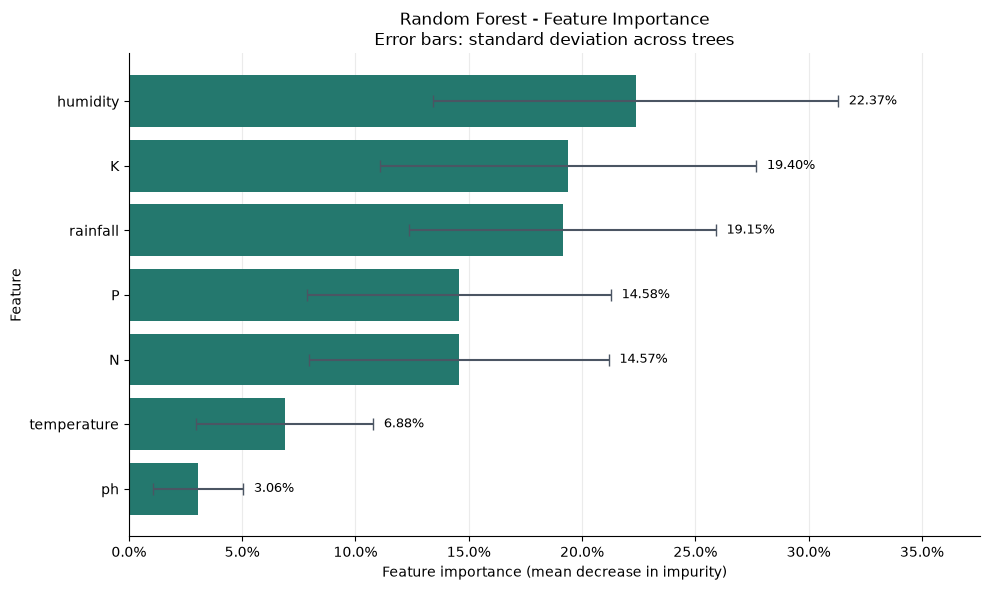

In [6]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns.tolist(),
    "Importance": model.feature_importances_,
    "Std_across_trees": np.std(
        [tree.feature_importances_ for tree in model.estimators_], axis=0, ddof=0
    ),
}).sort_values("Importance", ascending=False).reset_index(drop=True)
feature_importance.insert(0, "Rank", range(1, len(feature_importance) + 1))
display(feature_importance)
feature_importance.to_csv(model_dir / "feature_importance.csv", index=False)

plot_data = feature_importance.sort_values("Importance", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data["Feature"], plot_data["Importance"],
    xerr=plot_data["Std_across_trees"], capsize=4,
    color="#24786E", ecolor="#4B5563",
)
max_extent = float((plot_data["Importance"] + plot_data["Std_across_trees"]).max())
ax.set_xlim(0, max_extent * 1.2)
for bar, importance, std in zip(
    bars, plot_data["Importance"], plot_data["Std_across_trees"]
):
    ax.text(
        importance + std + max_extent * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{importance:.2%}", va="center", fontsize=9,
    )
ax.set_title("Random Forest - Feature Importance\nError bars: standard deviation across trees")
ax.set_xlabel("Feature importance (mean decrease in impurity)")
ax.set_ylabel("Feature")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
for extension in ("png", "svg"):
    output_path = model_dir / f"feature_importance.{extension}"
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    if extension == "svg":
        svg = output_path.read_text(encoding="utf-8")
        output_path.write_text(
            "\n".join(line.rstrip() for line in svg.splitlines()) + "\n", encoding="utf-8"
        )
plt.show()
plt.close(fig)

## 7. Lưu kết quả đánh giá

In [8]:
evaluated_at = timestamp()
evaluation = {
    "model_name": "Random Forest", "evaluated_at": evaluated_at,
    "feature_importance_method": "mean_decrease_in_impurity",
    "feature_importance": feature_importance.to_dict(orient="records"),
    "tables": {
        "Tong_hop": summary.to_dict(orient="records"),
        "GridSearch": grid.to_dict(orient="records"),
    },
}
selected = summary.iloc[0]
metadata = {
    "model_file": "model.joblib", "model_name": "Random Forest",
    "estimator": "RandomForestClassifier", "configuration": "GridSearch",
    "parameters": search.best_params_, "preprocessing": "None (raw features)",
    "input_format": "Unscaled feature values in the order listed in features",
    "features": X_train.columns.tolist(), "classes": classes,
    "selection_metric": "CV_f1_macro_mean",
    "cv_f1_macro_mean": float(selected["CV_f1_macro_mean"]),
    "cv_f1_macro_std": float(selected["CV_f1_macro_std"]),
    "train_samples": len(X_train), "test_samples": len(X_test),
    "n_splits": search.n_splits_, "cv_method": str(search.cv),
    "training_finished_at": artifact["finished_at"],
    "versions": artifact["versions"], "evaluated_at": evaluated_at,
    "feature_importance": {
        "method": "mean_decrease_in_impurity",
        "source": "RandomForestClassifier.feature_importances_",
        "csv_file": "feature_importance.csv",
        "visualization_png": "feature_importance.png",
        "visualization_svg": "feature_importance.svg",
    },
    "test_metrics": {
        "accuracy": float(selected["Test_accuracy"]),
        "precision_macro": float(selected["Test_precision_macro"]),
        "recall_macro": float(selected["Test_recall_macro"]),
        "f1_macro": float(selected["Test_f1_macro"]),
    },
}
write_json(model_dir / "model_metadata.json", metadata)
write_json(model_dir / "evaluation_results.json", evaluation)